In [1]:
"""
Calculate and output a table of the percentage of each behaviour labelled 
for each of the 14 individuals.
"""

import os
import re
import json
from collections import defaultdict
import numpy as np
import pandas as pd

# --- Configuration & Paths ---
DIR_IN = "Data"
RESAMPLING_STEP_S = 0.0500
COL_BEH = 27
DESCRIPTORS_SELEC = [1, 2, 3, 4, 5, 6, 25]
DESCRIPTORS_SELEC2 = [0, 1, 2, 3, 4, 5, 24]

# --- Behavior Classes Definition ---
class classCLASS:
    def __init__(self, id, name, behaviors, score_weight, sampling_weight=1, loss_weight=1):
        self.id = id
        self.name = name
        self.behaviors = behaviors
        self.score_weight = score_weight
        self.sampling_weight = sampling_weight
        self.loss_weight = loss_weight

Other      = classCLASS(0, "Other", None, 0, 1, 0.1)
Breathing  = classCLASS(1, "Breathing", [1, 2, 40], 1)
Feeding    = classCLASS(2, "Feeding", [3, 4, 5, 6, 7, 11, 12, 13, 18, 19, 20, 21], 10, 2, 2)
Gliding    = classCLASS(3, "Gliding", [16, 17], 1, 3)
Resting    = classCLASS(4, "Resting", [29, 30, 31, 32], 1, 0.5)
Scratching = classCLASS(5, "Scratching", [34, 35, 36], 2, 2, 2)
Swimming   = classCLASS(6, "Swimming", [42, 45, 48, 43, 46, 49, 27, 44, 47, 50, 56, 52, 54, 55], 1, 0.5)

CLASSES = [Other, Breathing, Feeding, Gliding, Resting, Scratching, Swimming]
CLASS_NAMES = [c.name for c in CLASSES]

# --- Recordings & Individual Groupings ---
NAMES_ALL = [
    'CC-07-48_18-02-2019',
    'CC-07-48_06-10-2018',
    'CC-07-48_04-10-2018',
    'CC-07-115_13-05-2019',
    'CC-07-115_14-05-2019',
    'CC-07-48_08-04-2019_1',
    'CC-07-48_08-04-2019_2',
    'CC-07-48_08-04-2019_3',
    'CC-07-48_22-05-2018',
    'CC-07-108_11-02-2019',
    'CC-07-59_20-05-2018',
    'CC-07-47_14-02-2018',
    'CC-07-48_10-10-2018',
    'CC-07-48_08-10-2018',
    'CC-07-48_26-05-2018',
    'CC-07-107_11-02-2019',
    'CC-09-72_04-11-2022'
]

INDIVIDUAL_OVERRIDES = {
    'CC-07-115_13-05-2019': 'CC-07-115_13-05-2019+14-05-2019',
    'CC-07-115_14-05-2019': 'CC-07-115_13-05-2019+14-05-2019',
}

def individual_id_of(name):
    if name in INDIVIDUAL_OVERRIDES:
        return INDIVIDUAL_OVERRIDES[name]
    return re.sub(r'_\d+$', '', name)

INDIVIDUAL_TO_NAMES = defaultdict(list)
for name in NAMES_ALL:
    INDIVIDUAL_TO_NAMES[individual_id_of(name)].append(name)

INDIVIDUAL_IDS = sorted(INDIVIDUAL_TO_NAMES.keys())

def load_labels(names):
    """Loads labels for the specified recording names."""
    labels = {}
    for name in names:
        full_name = os.path.join(DIR_IN, "out_A_09062025", f"{name}.npy")
        if not os.path.exists(full_name):
            full_name = os.path.join(DIR_IN, "out_B", f"{name}.npy")
            full_mat = np.load(full_name)
            pre_label = full_mat[:, COL_BEH - 1]
        else:
            full_mat = np.load(full_name)
            pre_label = full_mat[:, COL_BEH]

        label = np.zeros_like(pre_label)
        for c in CLASSES:
            if c != Other:
                for beh in c.behaviors:
                    label[pre_label == beh] = c.id
        labels[name] = label
    return labels

def main():
    print(f"Loading labels for {len(NAMES_ALL)} recordings across {len(INDIVIDUAL_IDS)} individuals...")
    labels = load_labels(NAMES_ALL)

    individual_rows = []

    for iid in INDIVIDUAL_IDS:
        recording_names = INDIVIDUAL_TO_NAMES[iid]
        
        # Aggregate counts across all recordings belonging to this individual
        counts = np.zeros(len(CLASSES), dtype=np.int64)
        total_steps = 0
        
        for name in recording_names:
            lab = labels[name]
            total_steps += len(lab)
            for c in CLASSES:
                counts[c.id] += np.sum(lab == c.id)

        # Calculate percentages
        if total_steps > 0:
            percentages = (counts / total_steps) * 100
        else:
            percentages = np.zeros(len(CLASSES))

        row = {"individual": iid, "total_hours": (total_steps * RESAMPLING_STEP_S) / 3600}
        for idx, c_name in enumerate(CLASS_NAMES):
            row[f"{c_name}_%"] = round(percentages[idx], 2)
            row[f"{c_name}_timesteps"] = counts[idx]
            
        individual_rows.append(row)

    df_results = pd.DataFrame(individual_rows)
    
    # Reorder columns for clean display (percentages first, then total hours)
    pct_cols = [f"{c}_%" for c in CLASS_NAMES]
    display_cols = ["individual", "total_hours"] + pct_cols
    
    print("\n--- Behaviour Percentage Table by Individual ---")
    print(df_results[display_cols].to_string(index=False))

    # Save to CSV
    os.makedirs("Model_results", exist_ok=True)
    out_path = "Model_results/individual_behavior_percentages.csv"
    df_results.to_string(out_path, index=False)
    print(f"\nTable successfully saved to {out_path}")

if __name__ == "__main__":
    main()

Loading labels for 17 recordings across 14 individuals...

--- Behaviour Percentage Table by Individual ---
                     individual  total_hours  Other_%  Breathing_%  Feeding_%  Gliding_%  Resting_%  Scratching_%  Swimming_%
           CC-07-107_11-02-2019     4.807528     2.00         6.30       5.95       7.26      41.55          0.37       36.57
           CC-07-108_11-02-2019     2.226278     3.36        10.55       8.24       1.61       7.52          0.26       68.47
CC-07-115_13-05-2019+14-05-2019    14.670486     0.51         6.70       0.34       4.30      51.96          0.41       35.78
            CC-07-47_14-02-2018     1.463361     0.00         0.68       0.00       0.00       0.00          0.00       99.32
            CC-07-48_04-10-2018     3.944736     1.00        12.39       1.07       1.49      40.89          0.06       43.10
            CC-07-48_06-10-2018     6.599764     3.61        11.06       8.21       1.19      47.57          3.80       24.56
          

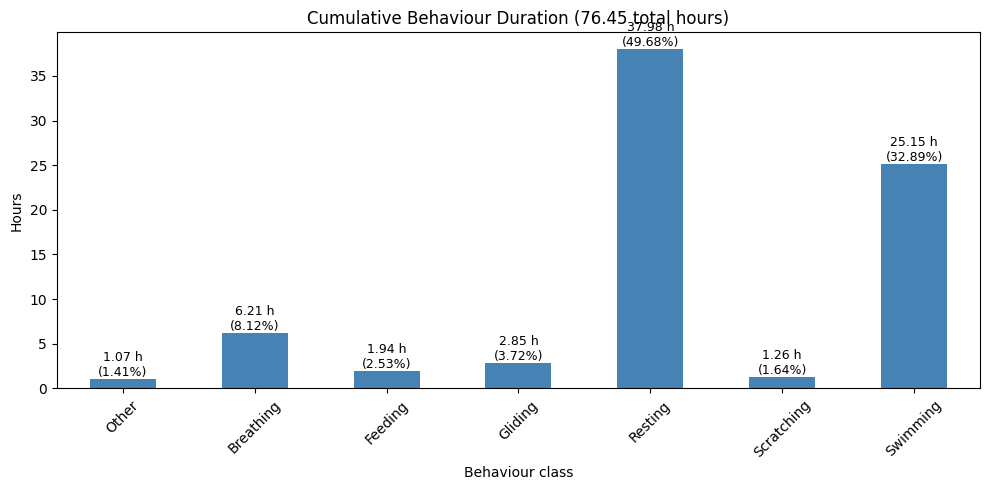

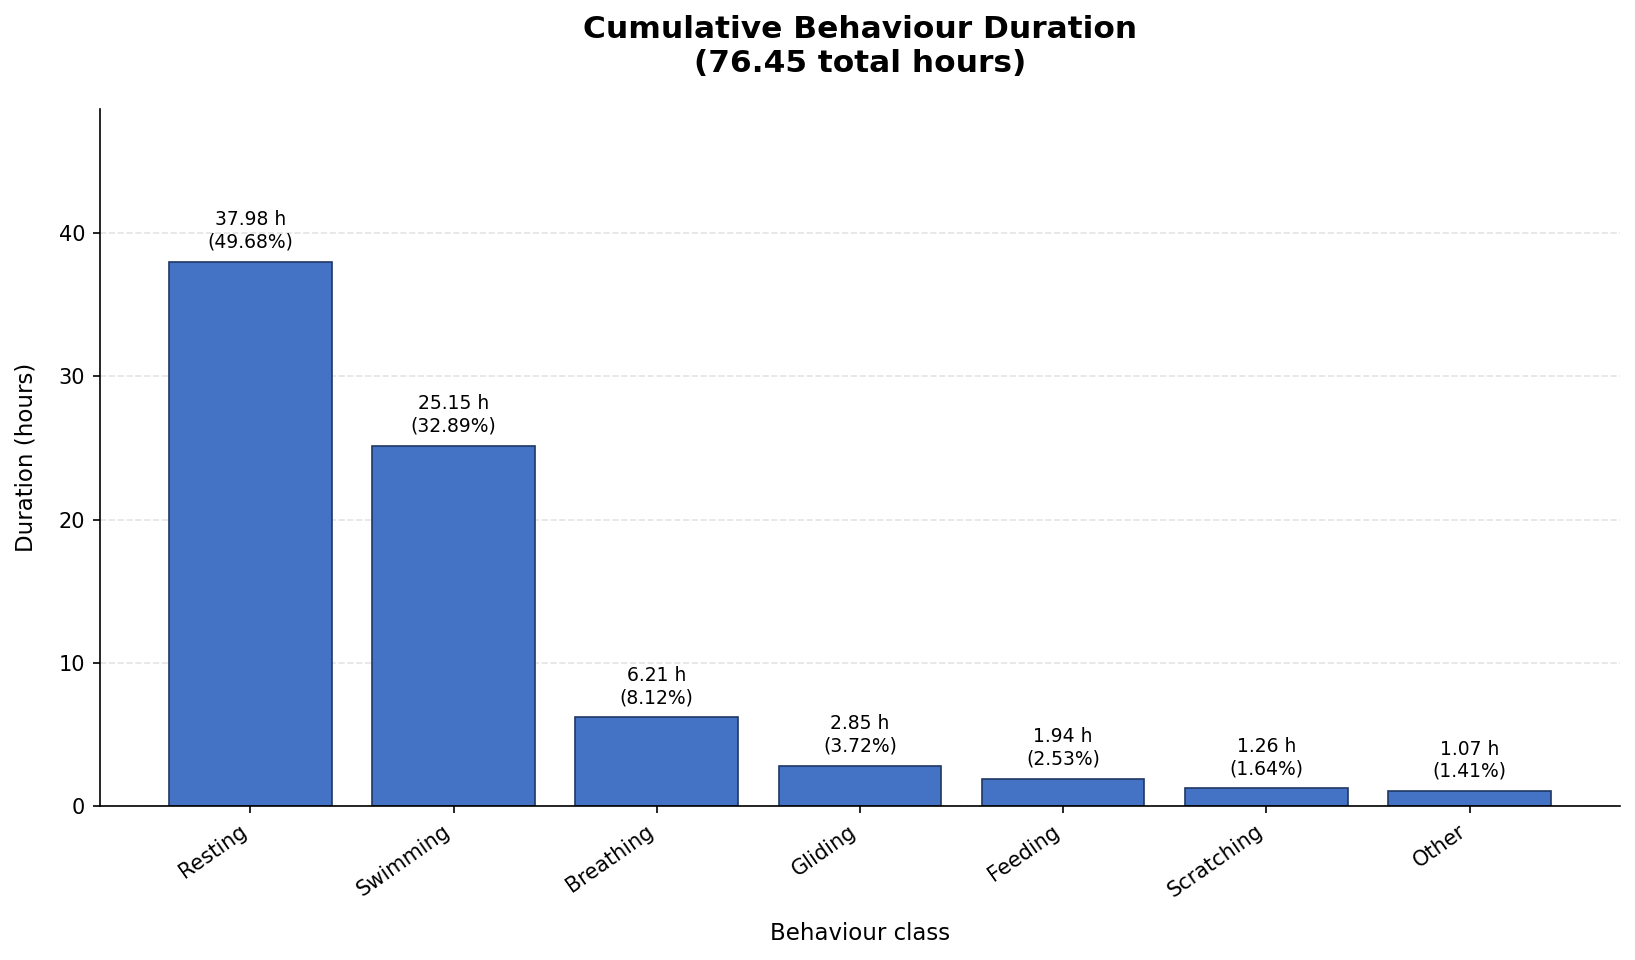

,behavior,hours,percentage,timesteps
0,Resting,37.982500,49.682908,2734740
1,Swimming,25.147250,32.893793,1810602
2,Breathing,6.205069,8.116524,446765
3,Gliding,2.845972,3.722666,204910
4,Feeding,1.937917,2.534887,139530
5,Scratching,1.256806,1.643961,90490
6,Other,1.074319,1.405261,77351


In [4]:
import matplotlib.pyplot as plt

def plot_cumulative_behavior_hours(labels=None):
    """Aggregate behavior durations across all recordings and plot hours and percentages."""
    if labels is None:
        labels = load_labels(NAMES_ALL)

    counts = np.zeros(len(CLASSES), dtype=np.int64)

    for recording_labels in labels.values():
        for behavior_class in CLASSES:
            counts[behavior_class.id] += np.sum(
                recording_labels == behavior_class.id
            )

    total_steps = counts.sum()
    total_hours = total_steps * RESAMPLING_STEP_S / 3600

    summary = pd.DataFrame({
        "behavior": CLASS_NAMES,
        "hours": counts * RESAMPLING_STEP_S / 3600,
        "percentage": (counts / total_steps * 100) if total_steps else 0,
        "timesteps": counts,
    })

    ax = summary.plot(
        x="behavior",
        y="hours",
        kind="bar",
        legend=False,
        figsize=(10, 5),
        color="steelblue",
    )

    ax.set_title(f"Cumulative Behaviour Duration ({total_hours:.2f} total hours)")
    ax.set_xlabel("Behaviour class")
    ax.set_ylabel("Hours")
    ax.tick_params(axis="x", rotation=45)

    for bar, percentage in zip(ax.patches, summary["percentage"]):
        ax.annotate(
            f"{bar.get_height():.2f} h\n({percentage:.2f}%)",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center",
            va="bottom",
            fontsize=9,
        )

    plt.tight_layout()
    plt.show()

    return summary

cumulative_behavior_summary = plot_cumulative_behavior_hours()
def plot_cumulative_behavior_hours(labels=None):
    """Plot cumulative behaviour duration, ordered from highest to lowest."""
    if labels is None:
        labels = load_labels(NAMES_ALL)

    counts = np.zeros(len(CLASSES), dtype=np.int64)

    for recording_labels in labels.values():
        for behavior_class in CLASSES:
            counts[behavior_class.id] += np.sum(
                recording_labels == behavior_class.id
            )

    total_steps = counts.sum()
    total_hours = total_steps * RESAMPLING_STEP_S / 3600

    summary = pd.DataFrame({
        "behavior": CLASS_NAMES,
        "hours": counts * RESAMPLING_STEP_S / 3600,
        "percentage": (
            counts / total_steps * 100 if total_steps else np.zeros(len(counts))
        ),
        "timesteps": counts,
    }).sort_values("hours", ascending=False).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(11, 6.5), dpi=150)

    bars = ax.bar(
        summary["behavior"],
        summary["hours"],
        color="#4472C4",
        edgecolor="#1F3864",
        linewidth=0.8,
    )

    ax.set_title(
        f"Cumulative Behaviour Duration\n"
        f"({total_hours:.2f} total hours)",
        fontsize=15,
        fontweight="bold",
        pad=18,
    )
    ax.set_xlabel("Behaviour class", fontsize=11, labelpad=10)
    ax.set_ylabel("Duration (hours)", fontsize=11, labelpad=10)

    ax.tick_params(axis="x", rotation=35, labelsize=10)
    ax.tick_params(axis="y", labelsize=10)
    plt.setp(ax.get_xticklabels(), ha="right")

    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    max_hours = summary["hours"].max() if not summary.empty else 0
    ax.set_ylim(0, max_hours * 1.28 if max_hours > 0 else 1)

    for bar, percentage in zip(bars, summary["percentage"]):
        height = bar.get_height()
        ax.annotate(
            f"{height:.2f} h\n({percentage:.2f}%)",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            clip_on=False,
        )

    fig.tight_layout()
    plt.show()

    return summary


cumulative_behavior_summary = plot_cumulative_behavior_hours()
cumulative_behavior_summary